GD MSE: 1.292327655590046 R2: 0.013798228607320828
Normal Equation MSE: 1.2923314440807299 R2: 0.013795337532284901


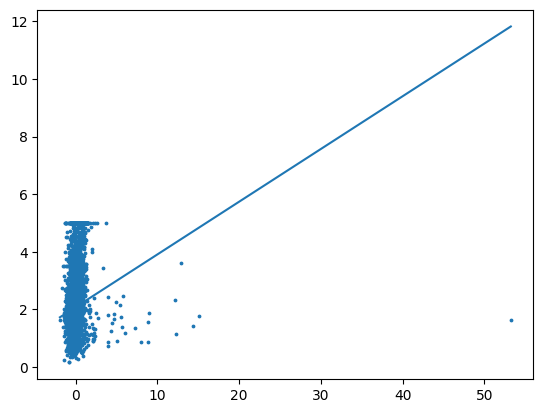

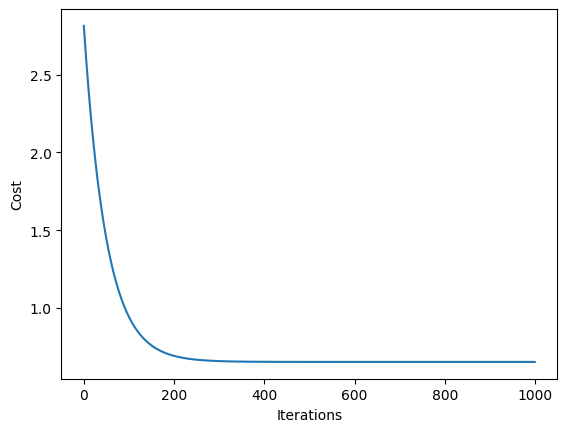

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

d = fetch_california_housing(as_frame=True).frame
X, y = d[['AveRooms']].values, d.MedHouseVal.values
x, z, Y, Z = train_test_split(X, y, test_size=.2, random_state=42)
s = StandardScaler()
x, z = s.fit_transform(x), s.transform(z)
A, B = np.c_[np.ones(len(x)), x], np.c_[np.ones(len(z)), z]

t, c = np.zeros(2), []
for _ in range(1000):
    e = A @ t - Y
    t -= .01 * A.T @ e / len(Y)
    c.append(np.mean(e**2)/2)
p = B @ t

u = np.linalg.pinv(A) @ Y
q = B @ u

for n, v in [('GD', p), ('Normal Equation', q)]:
    print(n, 'MSE:', mean_squared_error(Z, v), 'R2:', r2_score(Z, v))

i = np.argsort(z[:, 0])
plt.scatter(z, Z, s=3); plt.plot(z[i], p[i]); plt.show()
plt.plot(c); plt.xlabel('Iterations'); plt.ylabel('Cost'); plt.show()
